In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from prophet import Prophet

c:\Users\saile\OneDrive\Desktop\research\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


In [2]:
df = pd.read_csv(r"C:\Users\saile\OneDrive\Desktop\research\data\final_cleaned.csv")
df.head()

,item_id,store_id,sales,date,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,sell_price
0,FOODS_3_586,CA_2,34,2011-01-29,NaN,NaN,NaN,NaN,0,1.48
1,FOODS_3_555,CA_3,18,2011-01-29,NaN,NaN,NaN,NaN,0,1.48
2,FOODS_3_080,CA_2,21,2011-01-29,NaN,NaN,NaN,NaN,0,1.48
3,FOODS_3_080,CA_3,28,2011-01-29,NaN,NaN,NaN,NaN,0,1.48
4,FOODS_3_389,CA_3,15,2011-01-29,NaN,NaN,NaN,NaN,0,1.48


In [3]:
cleaned = df[
    df["store_id"].isin(["CA_2"]) &
    df["item_id"].isin(["FOODS_3_586"])
]
cleaned.reset_index(drop = True, inplace = True)
cleaned

,item_id,store_id,sales,date,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,sell_price
0,FOODS_3_586,CA_2,34,2011-01-29,NaN,NaN,NaN,NaN,0,1.48
1,FOODS_3_586,CA_2,25,2011-01-30,NaN,NaN,NaN,NaN,0,1.48
2,FOODS_3_586,CA_2,16,2011-01-31,NaN,NaN,NaN,NaN,0,1.48
3,FOODS_3_586,CA_2,25,2011-02-01,NaN,NaN,NaN,NaN,1,1.48
4,FOODS_3_586,CA_2,37,2011-02-02,NaN,NaN,NaN,NaN,1,1.48
...,...,...,...,...,...,...,...,...,...,...
1908,FOODS_3_586,CA_2,42,2016-04-20,NaN,NaN,NaN,NaN,0,1.68
1909,FOODS_3_586,CA_2,30,2016-04-21,NaN,NaN,NaN,NaN,0,1.68
1910,FOODS_3_586,CA_2,34,2016-04-22,NaN,NaN,NaN,NaN,0,1.68
1911,FOODS_3_586,CA_2,39,2016-04-23,NaN,NaN,NaN,NaN,0,1.68


In [4]:
cleaned.dtypes

item_id             str
store_id            str
sales             int64
date                str
event_name_1        str
event_type_1        str
event_name_2        str
event_type_2        str
snap_CA           int64
sell_price      float64
dtype: object

In [5]:
cleaned['date'] = pd.to_datetime(cleaned['date'])

In [6]:
cleaned.dtypes

item_id                    str
store_id                   str
sales                    int64
date            datetime64[us]
event_name_1               str
event_type_1               str
event_name_2               str
event_type_2               str
snap_CA                  int64
sell_price             float64
dtype: object

In [7]:
cleaned = cleaned.rename(columns={"date": "ds" , "sales": "y"})
cleaned

,item_id,store_id,y,ds,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,sell_price
0,FOODS_3_586,CA_2,34,2011-01-29,NaN,NaN,NaN,NaN,0,1.48
1,FOODS_3_586,CA_2,25,2011-01-30,NaN,NaN,NaN,NaN,0,1.48
2,FOODS_3_586,CA_2,16,2011-01-31,NaN,NaN,NaN,NaN,0,1.48
3,FOODS_3_586,CA_2,25,2011-02-01,NaN,NaN,NaN,NaN,1,1.48
4,FOODS_3_586,CA_2,37,2011-02-02,NaN,NaN,NaN,NaN,1,1.48
...,...,...,...,...,...,...,...,...,...,...
1908,FOODS_3_586,CA_2,42,2016-04-20,NaN,NaN,NaN,NaN,0,1.68
1909,FOODS_3_586,CA_2,30,2016-04-21,NaN,NaN,NaN,NaN,0,1.68
1910,FOODS_3_586,CA_2,34,2016-04-22,NaN,NaN,NaN,NaN,0,1.68
1911,FOODS_3_586,CA_2,39,2016-04-23,NaN,NaN,NaN,NaN,0,1.68


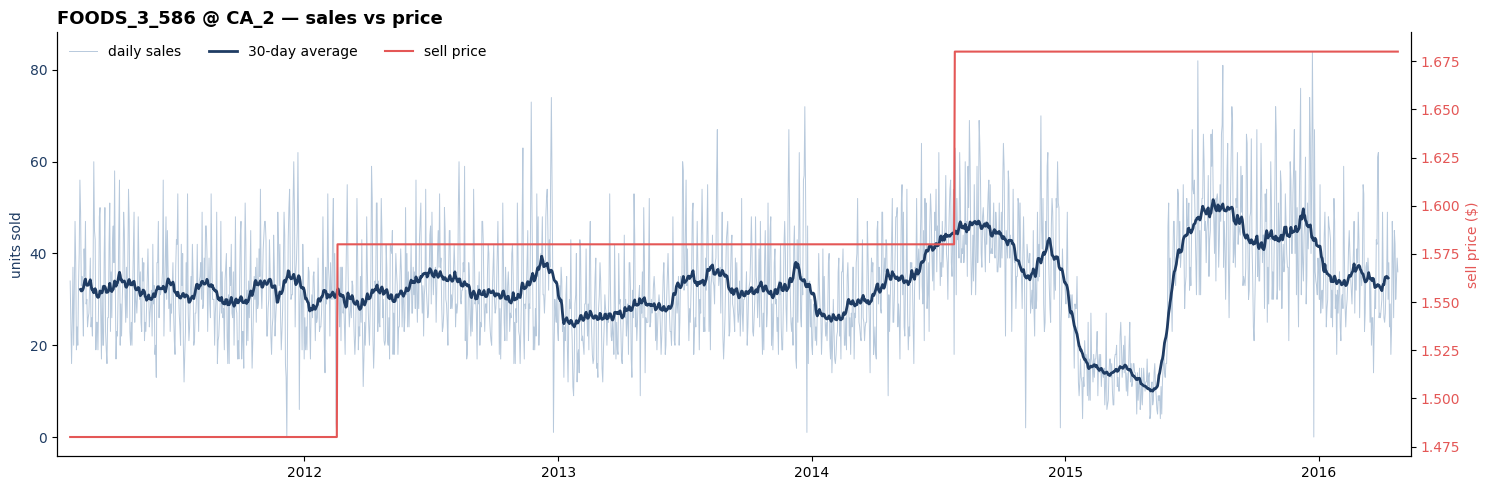

In [8]:
fig, ax1 = plt.subplots(figsize=(15, 5))

# --- left axis: sales ---
l1, = ax1.plot(cleaned["ds"], cleaned["y"],
               color="#4C78A8", lw=0.7, alpha=0.4, label="daily sales")
l2, = ax1.plot(cleaned["ds"], cleaned["y"].rolling(30, center=True).mean(),
               color="#1F3C63", lw=2, label="30-day average")
ax1.set_ylabel("units sold", color="#1F3C63")
ax1.tick_params(axis="y", labelcolor="#1F3C63")

# --- right axis: price ---
ax2 = ax1.twinx()
l3, = ax2.plot(cleaned["ds"], cleaned["sell_price"],
               color="#E45756", lw=1.5, label="sell price")
ax2.set_ylabel("sell price ($)", color="#E45756")
ax2.tick_params(axis="y", labelcolor="#E45756")
ax2.grid(False)                       # stops the second axis drawing its own gridlines

# --- one combined legend across both axes ---
ax1.legend(handles=[l1, l2, l3], loc="upper left", frameon=False, fontsize=10, ncol=3)

ax1.set_title("FOODS_3_586 @ CA_2 — sales vs price", fontsize=13, fontweight="bold", loc="left")
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.margins(x=0.01)
ax1.spines["top"].set_visible(False)  # hide only the top spine — the right one is now the price axis
ax2.spines["top"].set_visible(False)
plt.tight_layout()
plt.show()

In [9]:
window = cleaned[(cleaned["ds"] >= "2015-01-01") & (cleaned["ds"] <= "2015-07-01")]
print(window["y"].describe())
print("zero-sales days:", (window["y"] == 0).sum())
print("days under 5 :", (window["y"] < 5).sum())
print(window[window["y"] < 10][["ds", "y"]].to_string(index=False))   # the low run itself

count    182.000000
mean      20.093407
std       12.376553
min        4.000000
25%       11.250000
50%       16.000000
75%       27.000000
max       55.000000
Name: y, dtype: float64
zero-sales days: 0
days under 5 : 3
        ds  y
2015-01-21  9
2015-01-26  4
2015-02-02  9
2015-02-04  8
2015-02-06  8
2015-02-17  9
2015-02-27  7
2015-03-02  6
2015-03-03  7
2015-03-04  8
2015-03-11  7
2015-03-12  7
2015-04-01  9
2015-04-14  5
2015-04-16  8
2015-04-19  6
2015-04-20  8
2015-04-22  7
2015-05-03  4
2015-05-04  5
2015-05-07  7
2015-05-08  8
2015-05-12  9
2015-05-13  6
2015-05-14  5
2015-05-15  9
2015-05-16  8
2015-05-17  9
2015-05-18  4
2015-05-20  5


In [10]:
baseline = cleaned.loc[cleaned["event_name_1"].isna()
                     & cleaned["event_name_2"].isna(), "y"].mean()

holidays = cleaned[cleaned["event_name_1"].notna()][["ds", "event_name_1"]].rename(columns={"event_name_1": "holiday"}).drop_duplicates()

audit = (holidays.merge(cleaned[["ds", "y"]], on="ds")
                 .groupby("holiday")["y"]
                 .agg(n="count", mean_sales="mean")
                 .assign(uplift_pct=lambda d: (d["mean_sales"]/baseline - 1) * 100)
                 .sort_values("uplift_pct", ascending=False))
print(f"non-event baseline: {baseline:.1f}")
print(audit)

non-event baseline: 33.2
                     n  mean_sales  uplift_pct
holiday                                       
Thanksgiving         5   55.600000   67.509463
IndependenceDay      5   45.000000   35.574206
EidAlAdha            5   44.200000   33.163998
LaborDay             5   42.000000   26.535925
VeteransDay          5   41.000000   23.523165
Eid al-Fitr          5   40.800000   22.920613
Father's day         4   40.250000   21.263595
NBAFinalsEnd         5   39.600000   19.305301
Mother's day         5   39.400000   18.702749
OrthodoxEaster       4   37.750000   13.731695
Easter               5   36.800000   10.869573
Halloween            5   36.000000    8.459365
Ramadan starts       5   36.000000    8.459365
Purim End            6   33.666667    1.429591
Chanukah End         5   32.800000   -1.181468
ValentinesDay        6   31.666667   -4.595929
SuperBowl            6   30.166667   -9.115070
MemorialDay          5   29.800000  -10.219748
ColumbusDay          5   29.600000 

In [11]:
CUTOFF = "2015-11-01"                     # decision point ~4 weeks before Thanksgiving 2015
train = cleaned[cleaned["ds"] < CUTOFF]   # 2011 → Oct 2015: contains 4 Thanksgivings to learn from

m = Prophet(
    holidays=holidays,          # your step-4 table (holdout TG date included — known in advance, not leakage)
    interval_width=0.90,        # 90% band; real Newsvendor quantiles come from samples later
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
)
m.add_regressor("snap_CA")      # SNAP enters here, not via the holidays table

m.fit(train[["ds", "y", "snap_CA"]])

# predict over the FULL span — regressor values come straight from `cleaned`,
# which sidesteps the classic make_future_dataframe missing-regressor trap
future = cleaned[["ds", "snap_CA"]].copy()
forecast = m.predict(future)

03:31:20 - cmdstanpy - INFO - Chain [1] start processing
03:31:21 - cmdstanpy - INFO - Chain [1] done processing


holdout MAE: 10.34 units | 90% interval coverage: 80%
        ds  y  yhat  yhat_lower  yhat_upper
2015-11-23 40  28.1        12.6        43.9
2015-11-24 40  27.8        12.0        43.9
2015-11-25 53  28.7        12.5        43.9
2015-11-26 59  56.8        40.6        73.5
2015-11-27 67  36.6        20.9        51.7
        ds  Thanksgiving
2011-11-24          26.8
2012-11-22          26.8
2013-11-28          26.8
2014-11-27          26.8
2015-11-26          26.8


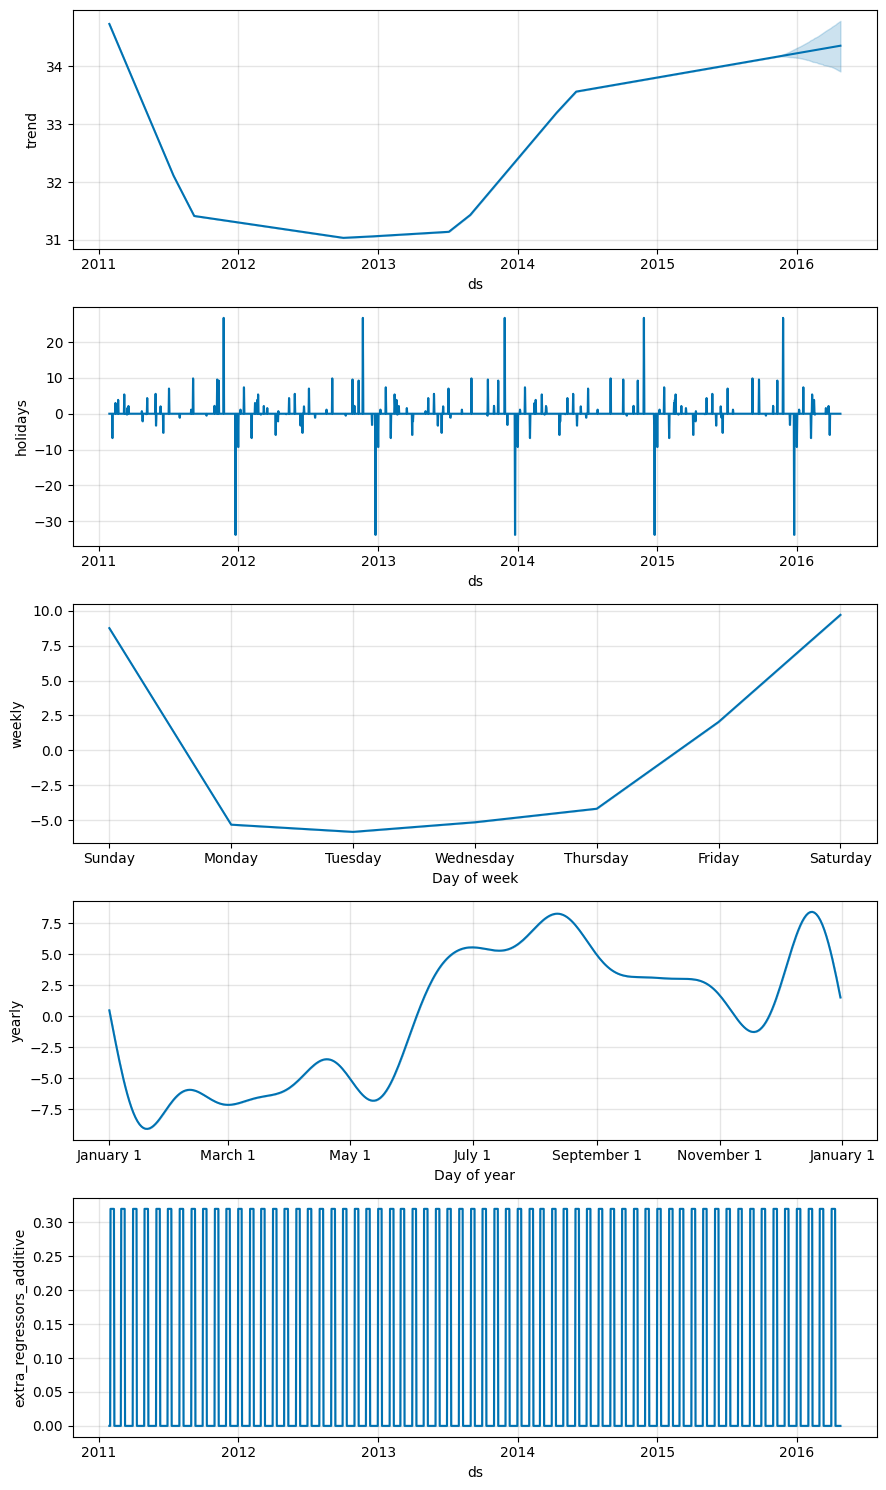

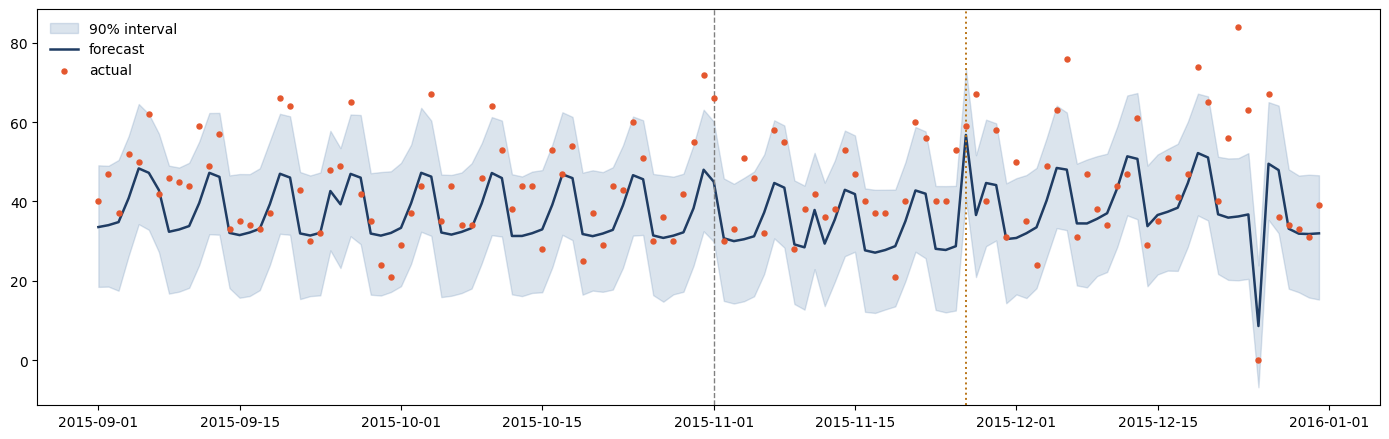

In [12]:
fc = forecast.merge(cleaned[["ds", "y"]], on="ds", how="left")
hold = fc[(fc["ds"] >= CUTOFF) & (fc["ds"] < "2016-01-01")]

mae = (hold["y"] - hold["yhat"]).abs().mean()
cov = ((hold["y"] >= hold["yhat_lower"]) & (hold["y"] <= hold["yhat_upper"])).mean()
print(f"holdout MAE: {mae:.2f} units | 90% interval coverage: {cov:.0%}")

# the week that matters
tgw = hold[(hold["ds"] >= "2015-11-23") & (hold["ds"] <= "2015-11-27")]
print(tgw[["ds","y","yhat","yhat_lower","yhat_upper"]]
      .to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# what Prophet learned for Thanksgiving, in units — compare to your audit
eff = forecast.loc[forecast["Thanksgiving"] != 0, ["ds", "Thanksgiving"]]
print(eff.tail(5).to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# component panels: trend / holidays / weekly / yearly / snap
m.plot_components(forecast); plt.show()

# zoom on the holdout
fig, ax = plt.subplots(figsize=(14, 4.5))
zoom = fc[(fc["ds"] >= "2015-09-01") & (fc["ds"] < "2016-01-01")]
ax.fill_between(zoom["ds"], zoom["yhat_lower"], zoom["yhat_upper"],
                color="#4C78A8", alpha=0.2, label="90% interval")
ax.plot(zoom["ds"], zoom["yhat"], color="#1F3C63", lw=1.8, label="forecast")
ax.scatter(zoom["ds"], zoom["y"], color="#E4572E", s=13, zorder=5, label="actual")
ax.axvline(pd.Timestamp(CUTOFF), color="gray", ls="--", lw=1)          # train | holdout
ax.axvline(pd.Timestamp("2015-11-26"), color="#BA7517", ls=":", lw=1.4)  # Thanksgiving
ax.legend(frameon=False); plt.tight_layout(); plt.show()

03:31:22 - cmdstanpy - INFO - Chain [1] start processing
03:31:22 - cmdstanpy - INFO - Chain [1] done processing



changepoint_range=0.8:  MAE 10.34 | coverage 79% | bias -8.12
        ds  y  yhat  yhat_lower  yhat_upper
2015-11-23 40  28.1        11.8        43.4
2015-11-24 40  27.8        11.9        43.1
2015-11-25 53  28.7        12.9        44.8
2015-11-26 59  56.8        42.5        72.4
2015-11-27 67  36.6        20.8        51.8


03:31:23 - cmdstanpy - INFO - Chain [1] start processing
03:31:23 - cmdstanpy - INFO - Chain [1] done processing



changepoint_range=0.95:  MAE 10.01 | coverage 74% | bias +5.59
        ds  y  yhat  yhat_lower  yhat_upper
2015-11-23 40  41.1        26.3        54.2
2015-11-24 40  40.9        26.9        54.6
2015-11-25 53  41.9        28.0        56.3
2015-11-26 59  70.1        56.6        83.5
2015-11-27 67  50.0        36.2        63.8


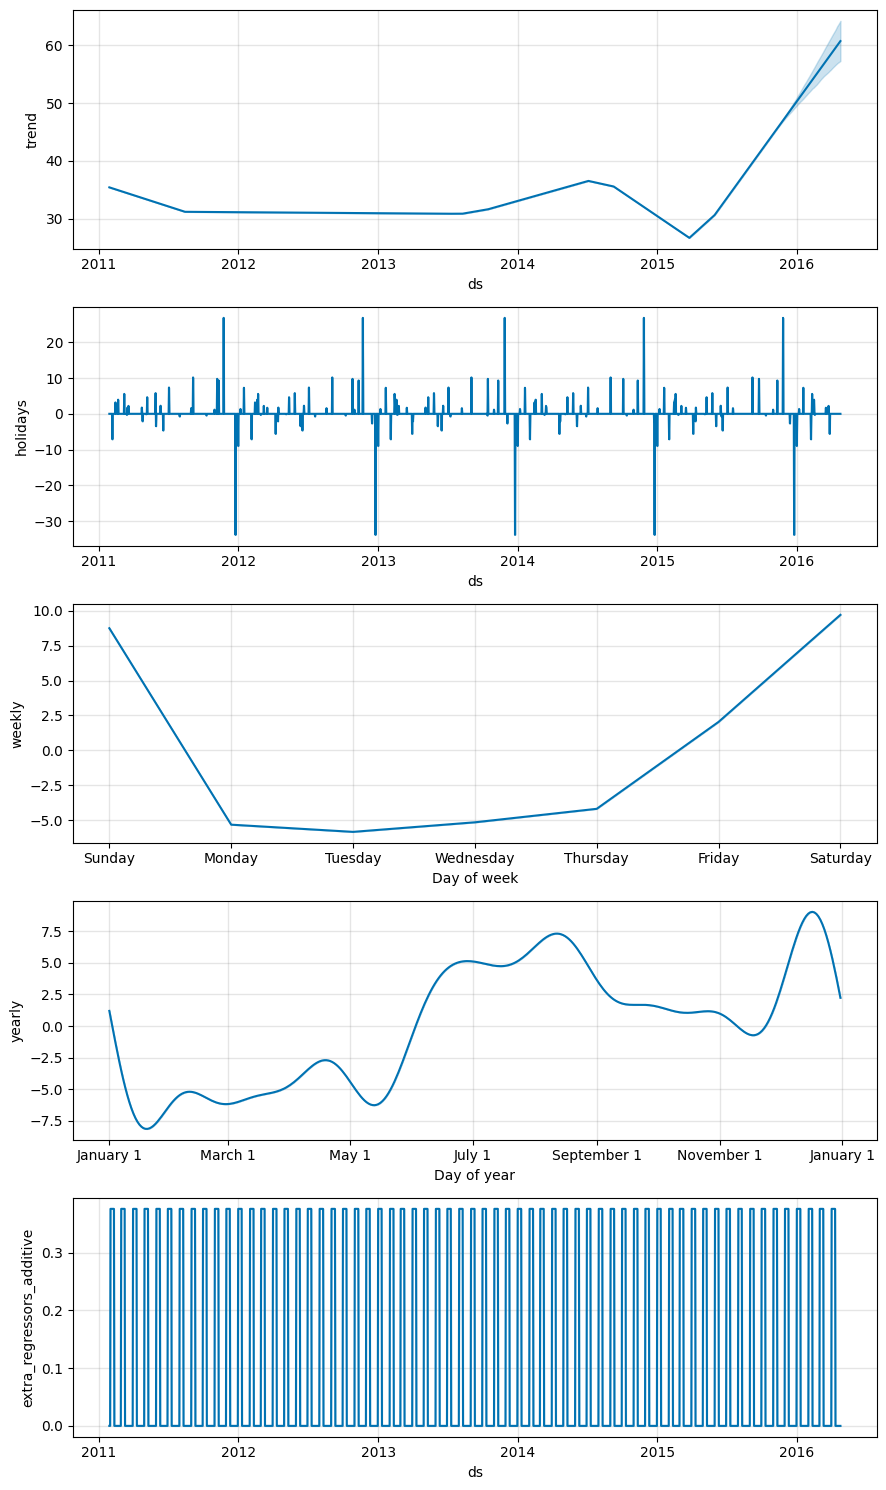

In [13]:
results = {}
for cr in [0.80, 0.95]:                      # 0.80 = default (current), 0.95 = allow late changepoints
    m = Prophet(holidays=holidays, interval_width=0.90,
                yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False,
                changepoint_range=cr)
    m.add_regressor("snap_CA")
    m.fit(train[["ds", "y", "snap_CA"]])
    fcst = m.predict(cleaned[["ds", "snap_CA"]].copy())
    f = fcst.merge(cleaned[["ds", "y"]], on="ds", how="left")
    h = f[(f["ds"] >= CUTOFF) & (f["ds"] < "2016-01-01")]

    mae  = (h["y"] - h["yhat"]).abs().mean()
    cov  = ((h["y"] >= h["yhat_lower"]) & (h["y"] <= h["yhat_upper"])).mean()
    bias = (h["yhat"] - h["y"]).mean()       # negative = systematically forecasting too low
    print(f"\nchangepoint_range={cr}:  MAE {mae:.2f} | coverage {cov:.0%} | bias {bias:+.2f}")
    tg = h[(h["ds"] >= "2015-11-23") & (h["ds"] <= "2015-11-27")]
    print(tg[["ds","y","yhat","yhat_lower","yhat_upper"]]
          .to_string(index=False, float_format=lambda v: f"{v:.1f}"))
    results[cr] = (m, fcst)

m, forecast = results[0.95]                  # keep the winner for the next step (swap if 0.80 wins)
m.plot_components(forecast); plt.show()

In [14]:
key = pd.to_datetime(["2015-11-01", "2015-11-26", "2015-12-25"])
print(forecast.loc[forecast["ds"].isin(key), ["ds", "trend", "yhat"]]
      .to_string(index=False, float_format=lambda v: f"{v:.1f}"))

        ds  trend  yhat
2015-11-01   44.7  54.8
2015-11-26   47.0  70.1
2015-12-25   49.7  24.7


In [15]:
rows = []
for cr, (mm, fcst) in results.items():
    f = fcst.merge(cleaned[["ds", "y"]], on="ds", how="left")
    h = f[(f["ds"] >= CUTOFF) & (f["ds"] < "2016-01-01")]
    for label, sub in [("full window", h),
                       ("excl. Dec 25", h[h["ds"] != "2015-12-25"])]:
        rows.append({"changepoint_range": cr, "window": label,
                     "MAE":  (sub["y"] - sub["yhat"]).abs().mean(),
                     "coverage": ((sub["y"] >= sub["yhat_lower"]) &
                                  (sub["y"] <= sub["yhat_upper"])).mean(),
                     "bias": (sub["yhat"] - sub["y"]).mean()})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

 changepoint_range       window   MAE  coverage  bias
              0.80  full window 10.34      0.79 -8.12
              0.80 excl. Dec 25 10.37      0.78 -8.40
              0.95  full window 10.01      0.74  5.59
              0.95 excl. Dec 25  9.77      0.75  5.27


In [16]:
rows = []
for cr, (mm, fcst) in results.items():
    f = fcst.merge(cleaned[["ds", "y"]], on="ds", how="left")
    for label, lo, hi in [("Nov (decision horizon)", "2015-11-01", "2015-12-01"),
                          ("Dec (beyond horizon)",  "2015-12-01", "2016-01-01"),
                          ("TG window",             "2015-11-23", "2015-11-28")]:
        s = f[(f["ds"] >= lo) & (f["ds"] < hi) & (f["ds"] != "2015-12-25")]
        rows.append({"cr": cr, "slice": label,
                     "MAE":      (s["y"] - s["yhat"]).abs().mean(),
                     "coverage": ((s["y"] >= s["yhat_lower"]) & (s["y"] <= s["yhat_upper"])).mean(),
                     "bias":     (s["yhat"] - s["y"]).mean()})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

  cr                  slice   MAE  coverage   bias
0.80 Nov (decision horizon) 10.17      0.83  -8.87
0.80   Dec (beyond horizon) 10.56      0.73  -7.94
0.80              TG window 16.22      0.60 -16.22
0.95 Nov (decision horizon)  7.36      0.87   3.25
0.95   Dec (beyond horizon) 12.17      0.63   7.28
0.95              TG window  8.25      0.80  -2.99


In [17]:
tg_dates = pd.date_range("2015-11-23", "2015-11-27")          # the event window
fut = cleaned.loc[cleaned["ds"].isin(tg_dates), ["ds", "snap_CA"]]

samples = m.predictive_samples(fut)                            # samples["yhat"]: shape (5 days, 1000 paths)
wt = np.clip(samples["yhat"], 0, None).sum(axis=0)             # clip: demand can't be negative; then sum DAYS within each path

actual_total = cleaned.loc[cleaned["ds"].isin(tg_dates), "y"].sum()
print(f"actual window total: {actual_total}")
print(f"forecast mean: {wt.mean():.0f}")
print({f"q{int(q*100)}": round(float(np.quantile(wt, q))) for q in [0.05, 0.25, 0.50, 0.70, 0.90, 0.95]})
print(f"actual sits at the {100*(wt < actual_total).mean():.0f}th percentile of the forecast distribution")

np.save("tg2015_window_samples.npy", wt)                       # the cached artifact downstream steps read

actual window total: 259
forecast mean: 243
{'q5': 212, 'q25': 230, 'q50': 244, 'q70': 253, 'q90': 268, 'q95': 276}
actual sits at the 80th percentile of the forecast distribution


In [18]:
# wt is the sampled window-total array (or: wt = np.load("tg2015_window_samples.npy"))

p = float(cleaned.loc[cleaned["ds"] == "2015-11-01", "sell_price"].iloc[0])   # price at decision time

MARGIN  = 0.30          # base case: cost = 70% of price
SALVAGE = 0.50          # base case: leftovers recovered at 50% of cost

c  = (1 - MARGIN) * p
s  = SALVAGE * c
Cu, Co = p - c, c - s
CR = Cu / (Cu + Co)
Q_star = float(np.quantile(wt, CR))
print(f"p={p:.2f} c={c:.2f} s={s:.2f} | Cu={Cu:.2f} Co={Co:.2f} | CR={CR:.2f} | Q*={Q_star:.0f}")

# sensitivity: does Q* actually move under different economic assumptions?
rows = []
for margin in [0.20, 0.30, 0.40]:
    for sv in [0.0, 0.5, 0.8]:
        c = (1 - margin) * p; s = sv * c
        cr = (p - c) / (p - s)
        rows.append({"margin": margin, "salvage": sv, "CR": cr,
                     "Q*": float(np.quantile(wt, cr))})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

p=1.68 c=1.18 s=0.59 | Cu=0.50 Co=0.59 | CR=0.46 | Q*=242
 margin  salvage   CR     Q*
   0.20     0.00 0.20 227.15
   0.20     0.50 0.33 234.74
   0.20     0.80 0.56 246.01
   0.30     0.00 0.30 233.19
   0.30     0.50 0.46 241.84
   0.30     0.80 0.68 252.11
   0.40     0.00 0.40 238.59
   0.40     0.50 0.57 246.93
   0.40     0.80 0.77 256.88


In [19]:
# ---- baseline: the model's no-event counterfactual for the same week ----
tg_fc = forecast[forecast["ds"].isin(tg_dates)]
event_units   = tg_fc["Thanksgiving"].sum()
baseline_total = (tg_fc["yhat"] - tg_fc["Thanksgiving"]).sum()
print(f"window forecast {tg_fc['yhat'].sum():.0f} = baseline {baseline_total:.0f} + event effect {event_units:.0f}")

# ---- expected profit under the sampled demand ----
def exp_profit(Q, d=wt, p=p, c=c, s=s):
    sales, leftover = np.minimum(Q, d), np.maximum(Q - d, 0)
    return float((p*sales - c*Q + s*leftover).mean())

grid = np.arange(180, 320)
pi = np.array([exp_profit(Q) for Q in grid])
print(f"profit-maximizing Q on grid: {grid[pi.argmax()]}  (internal check: should sit ≈ Q* = {Q_star:.0f})")

# ---- the decision rule ----
def decide(req_pct, base=baseline_total, eps_approve=0.02, min_uplift=0.05):
    Q_req = base * (1 + req_pct)
    regret = 1 - exp_profit(Q_req) / exp_profit(Q_star)
    pctl = (wt < Q_req).mean()
    if Q_req <= Q_star or regret <= eps_approve:
        verdict, Q_rec = "APPROVE", Q_req          # as asked (or economically immaterial)
    elif (Q_star - base) / base > min_uplift:
        verdict, Q_rec = "PARTIAL", Q_star         # increase warranted, but resized to optimal
    else:
        verdict, Q_rec = "REJECT", base            # no increase warranted — hold the line
    print(f"request +{req_pct:.0%}: Q_req={Q_req:.0f} (demand pctl {pctl:.0%}) | "
          f"regret if granted: {regret:.1%} | {verdict} → order {Q_rec:.0f}")

decide(0.50)   # the flagship scenario: manager asks +50% for Thanksgiving
decide(0.30)
decide(0.10)

window forecast 244 = baseline 217 + event effect 27
profit-maximizing Q on grid: 257  (internal check: should sit ≈ Q* = 242)
request +50%: Q_req=326 (demand pctl 100%) | regret if granted: 6.1% | PARTIAL → order 242
request +30%: Q_req=282 (demand pctl 97%) | regret if granted: 0.6% | APPROVE → order 282
request +10%: Q_req=239 (demand pctl 40%) | regret if granted: 0.5% | APPROVE → order 239


In [20]:
# --- re-pin base-case economics (the sensitivity loop overwrote c and s) ---
P_BASE = float(cleaned.loc[cleaned["ds"] == "2015-11-01", "sell_price"].iloc[0])
C_BASE = (1 - 0.30) * P_BASE          # margin 30%
S_BASE = 0.50 * C_BASE                # salvage 50% of cost
Cu, Co = P_BASE - C_BASE, C_BASE - S_BASE
CR = Cu / (Cu + Co)
Q_star = float(np.quantile(wt, CR))
print(f"re-pinned: Cu={Cu:.2f} Co={Co:.2f} CR={CR:.2f} Q*={Q_star:.0f}")

def exp_profit(Q, d=wt, p=P_BASE, c=C_BASE, s=S_BASE):
    sales, leftover = np.minimum(Q, d), np.maximum(Q - d, 0)
    return float((p*sales - c*Q + s*leftover).mean())

grid = np.arange(180, 320)
pi = np.array([exp_profit(Q) for Q in grid])
print(f"grid argmax: {grid[pi.argmax()]}  (must now sit ≈ {Q_star:.0f})")

decide(0.50); decide(0.30); decide(0.10)   # decide() picks up the fixed exp_profit/Q_star

re-pinned: Cu=0.50 Co=0.59 CR=0.46 Q*=242
grid argmax: 242  (must now sit ≈ 242)
request +50%: Q_req=326 (demand pctl 100%) | regret if granted: 35.1% | PARTIAL → order 242
request +30%: Q_req=282 (demand pctl 97%) | regret if granted: 13.0% | PARTIAL → order 242
request +10%: Q_req=239 (demand pctl 40%) | regret if granted: 0.1% | APPROVE → order 239


In [21]:
def evaluate_event_request(event_name, event_date, req_pcts=(0.50,),
                           margin=0.30, salvage=0.50, lead_days=28,
                           win_before=3, win_after=1,
                           eps_approve=0.02, min_uplift=0.05):
    event_date = pd.Timestamp(event_date)
    cutoff = event_date - pd.Timedelta(days=lead_days)          # decision made ~4 weeks out
    window = pd.date_range(event_date - pd.Timedelta(days=win_before),
                           event_date + pd.Timedelta(days=win_after))

    # --- fit the locked configuration on data available at decision time ---
    tr = cleaned[cleaned["ds"] < cutoff]
    mdl = Prophet(holidays=holidays, interval_width=0.90, changepoint_range=0.95,
                  yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
    mdl.add_regressor("snap_CA")
    mdl.fit(tr[["ds", "y", "snap_CA"]])

    # --- window-total demand distribution (seeded: reproducible) ---
    fut = cleaned.loc[cleaned["ds"].isin(window), ["ds", "snap_CA"]]
    np.random.seed(42)
    d = np.clip(mdl.predictive_samples(fut)["yhat"], 0, None).sum(axis=0)

    # --- baseline = model's no-event counterfactual for the same week ---
    fc = mdl.predict(fut)
    ev = fc[event_name].sum() if event_name in fc.columns else 0.0
    base = fc["yhat"].sum() - ev

    # --- economics at decision time ---
    p = float(cleaned.loc[cleaned["ds"] <= cutoff, "sell_price"].iloc[-1])
    c, s = (1 - margin) * p, salvage * (1 - margin) * p
    Q_star = float(np.quantile(d, (p - c) / (p - s)))
    def prof(Q):
        return float((p*np.minimum(Q, d) - c*Q + s*np.maximum(Q - d, 0)).mean())

    act = cleaned.loc[cleaned["ds"].isin(window), "y"].sum()
    print(f"{event_name} {event_date.date()} | cutoff {cutoff.date()} | "
          f"base {base:.0f} + event {ev:+.0f} | Q*={Q_star:.0f} | actual {act:.0f}")
    for r in req_pcts:
        Qr = base * (1 + r)
        regret = 1 - prof(Qr) / prof(Q_star)
        pctl = (d < Qr).mean()
        if Qr <= Q_star or regret <= eps_approve: v, Qrec = "APPROVE", Qr
        elif (Q_star - base) / base > min_uplift: v, Qrec = "PARTIAL", Q_star
        else:                                     v, Qrec = "REJECT",  base
        print(f"  +{r:.0%}: Q_req={Qr:.0f} (pctl {pctl:.0%}) | regret {regret:.1%} → {v} → order {Qrec:.0f}")

evaluate_event_request("SuperBowl",    "2016-02-07", req_pcts=(0.50, 0.20))
evaluate_event_request("Thanksgiving", "2015-11-26", req_pcts=(0.50, 0.30, 0.10))   # regression check

03:31:25 - cmdstanpy - INFO - Chain [1] start processing
03:31:25 - cmdstanpy - INFO - Chain [1] done processing


SuperBowl 2016-02-07 | cutoff 2016-01-10 | base 226 + event -7 | Q*=216 | actual 187
  +50%: Q_req=338 (pctl 100%) | regret 61.4% → REJECT → order 226
  +20%: Q_req=271 (pctl 100%) | regret 22.3% → REJECT → order 226


03:31:25 - cmdstanpy - INFO - Chain [1] start processing
03:31:26 - cmdstanpy - INFO - Chain [1] done processing


Thanksgiving 2015-11-26 | cutoff 2015-10-29 | base 216 + event +27 | Q*=241 | actual 259
  +50%: Q_req=324 (pctl 100%) | regret 34.9% → PARTIAL → order 241
  +30%: Q_req=281 (pctl 98%) | regret 12.8% → PARTIAL → order 241
  +10%: Q_req=238 (pctl 39%) | regret 0.1% → APPROVE → order 238


In [ ]:
import json

def evaluate_request(data, holidays, item_id, store_id, event_name, event_date, requested_pct=0.5,
                     margin=0.30, salvage=0.50, lead_days=28, win_before=3, win_after=1,
                     eps_approve=0.02, min_uplift=0.05):
    df = data[(data["item_id"] == item_id) & (data["store_id"] == store_id)].copy()
    df["ds"] = pd.to_datetime(df["ds"])
    df = df.sort_values("ds")

    event_date = pd.Timestamp(event_date)
    cutoff = event_date - pd.Timedelta(days=lead_days)
    window = pd.date_range(event_date - pd.Timedelta(days=win_before),
                           event_date + pd.Timedelta(days=win_after))

    tr = df[df["ds"] < cutoff]
    mdl = Prophet(
        holidays=holidays,
        interval_width=0.90,
        changepoint_range=0.95,
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
    )
    mdl.add_regressor("snap_CA")
    mdl.fit(tr[["ds", "y", "snap_CA"]])

    fut = df.loc[df["ds"].isin(window), ["ds", "snap_CA"]].copy()
    np.random.seed(42)
    demand_samples = np.clip(mdl.predictive_samples(fut)["yhat"], 0, None).sum(axis=0)

    fc = mdl.predict(fut)
    event_effect = float(fc[event_name].sum()) if event_name in fc.columns else 0.0
    baseline_total = float(fc["yhat"].sum() - event_effect)

    p = float(df.loc[df["ds"] <= cutoff, "sell_price"].iloc[-1])
    c = (1 - margin) * p
    s = salvage * c
    cu, co = p - c, c - s
    cr = cu / (cu + co)
    q_star = float(np.quantile(demand_samples, cr))

    def exp_profit(Q, d=demand_samples, p=p, c=c, s=s):
        sales = np.minimum(Q, d)
        leftover = np.maximum(Q - d, 0)
        return float((p * sales - c * Q + s * leftover).mean())

    requested_qty = baseline_total * (1 + requested_pct)
    regret = 1 - exp_profit(requested_qty) / exp_profit(q_star)
    demand_pctl = float((demand_samples < requested_qty).mean())

    if requested_qty <= q_star or regret <= eps_approve:
        decision, recommended_qty = "APPROVE", requested_qty
    elif (q_star - baseline_total) / baseline_total > min_uplift:
        decision, recommended_qty = "PARTIAL", q_star
    else:
        decision, recommended_qty = "REJECT", baseline_total

    return {
        "decision": decision,
        "requested_pct": requested_pct,
        "requested_qty": requested_qty,
        "recommended_qty": recommended_qty,
        "baseline_total": baseline_total,
        "event_effect": event_effect,
        "q_star": q_star,
        "regret": regret,
        "demand_percentile": demand_pctl,
        "actual_total": float(df.loc[df["ds"].isin(window), "y"].sum()),
        "cutoff": cutoff,
        "event_date": event_date,
        "demand_samples": demand_samples,
    }

r = evaluate_request(cleaned, holidays, "FOODS_3_586", "CA_2",
                     "Thanksgiving", "2015-11-26", requested_pct=0.5)
print(json.dumps({k: v for k, v in r.items() if k != "demand_samples"},
                 default=str, indent=2))

r2 = evaluate_request(cleaned, holidays, "FOODS_3_586", "CA_2",
                      "SuperBowl", "2016-02-07", requested_pct=0.5)
print(r2["decision"])
print(r2["decision"])

NameError: name 'evaluate_request' is not defined